# AI Code Review Bot for GitHub Pull Requests

**Problem:** skimming PR diffs for the obvious stuff (missing input validation, missing tests, log-noise) is repetitive. This notebook prototypes a bot that takes a unified diff, chunks per-file, asks an LLM for structured review comments, and "posts" them via a mocked GitHub call.

**Data:** 12 hand-rolled `.diff` files in `../../data/diffs/` covering a mix of categories: input validation, SQL injection fix, off-by-one, retry decorator, type hints, docstring-only changes, etc. Small enough to label by hand for a sanity-check precision number.

**Approach:** diff parser, per-file chunk, LLM with `response_format=json_object`, mocked PR comment poster.

**Not in this notebook:** the actual GitHub webhook / Action wiring. The `mock_post_github_comment` function shows what the call site would look like.

In [1]:
# !pip install fastapi uvicorn openai GitPython -q

In [2]:
import os
import re
import json
import textwrap
from pathlib import Path
from dotenv import load_dotenv
import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI

load_dotenv()
client = OpenAI()
MODEL = "gemini-flash-lite-latest"

DATA_DIR = Path("../../data/diffs")
assert DATA_DIR.exists(), "Add sample .diff or .patch files to data/diffs/"
os.makedirs("artifacts", exist_ok=True)

## Data Loading — sample diffs

Loaded 12 diffs


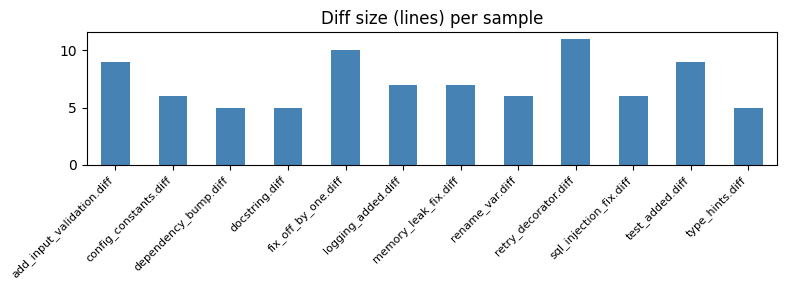

In [3]:
diff_files = sorted(DATA_DIR.glob("*.diff")) + sorted(DATA_DIR.glob("*.patch"))

diffs = []
for f in diff_files:
    text = f.read_text(errors="replace")
    lines = text.splitlines()
    diffs.append({"filename": f.name, "content": text, "lines": len(lines)})

df_diffs = pd.DataFrame(diffs)
print(f"Loaded {len(diffs)} diffs")

fig, ax = plt.subplots(figsize=(8, 3))
df_diffs["lines"].plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Diff size (lines) per sample")
ax.set_xticklabels(df_diffs["filename"], rotation=45, ha="right", fontsize=8)
plt.tight_layout()
plt.savefig("artifacts/diff_sizes.png", dpi=120)
plt.show()

## Preprocessing — parse and chunk diffs per file

In [4]:
def split_by_file(diff_text):
    """Split a unified diff into per-file chunks.

    Only `diff --git` lines mark a real file boundary. I used to also split on `--- `
    lines, but that double-counts because every git file diff has both, so the
    file count came out wrong on multi-file diffs.
    """
    chunks = []
    current_file = None
    current_lines = []
    for line in diff_text.splitlines():
        if line.startswith("diff --git"):
            if current_file and current_lines:
                chunks.append({"file": current_file, "diff": "\n".join(current_lines)})
            # 'diff --git a/path b/path' -> take the b/ side
            current_file = line.split(" b/")[-1] if " b/" in line else line
            current_lines = [line]
        else:
            current_lines.append(line)
    if current_file and current_lines:
        chunks.append({"file": current_file, "diff": "\n".join(current_lines)})
    return chunks

# test with first diff
if diffs:
    chunks = split_by_file(diffs[0]["content"])
    print(f"First diff splits into {len(chunks)} file chunks")

First diff splits into 1 file chunks


## Modeling — structured review prompt

In [5]:
REVIEW_SYSTEM = """You are a code reviewer. Given a unified diff for one file, return a JSON object with one key "comments" — a list of review comments.

Each comment has:
- "file": filename
- "line": approximate line number in the diff (int)
- "severity": "error" | "warning" | "nit"
- "category": "security" | "logic" | "performance" | "style" | "missing_test" | "other"
- "suggestion": concise actionable recommendation (one sentence)

If the diff looks clean, return {"comments": []}. Be strict — don't invent issues to look thorough.
"""

def _strip_fences(s: str) -> str:
    s = s.strip()
    if s.startswith("```"):
        s = re.sub(r"^```(?:json)?\s*", "", s)
        s = re.sub(r"\s*```$", "", s)
    return s

def review_diff_chunk(file_chunk):
    diff_text = file_chunk["diff"][:3000]
    resp = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "system", "content": REVIEW_SYSTEM},
            {"role": "user", "content": f"File: {file_chunk['file']}\n\n{diff_text}"},
        ],
        temperature=0,
        response_format={"type": "json_object"},
    )
    raw = _strip_fences(resp.choices[0].message.content)
    try:
        obj = json.loads(raw)
    except json.JSONDecodeError:
        return []
    # Tolerate the model returning either a bare list or {"comments": [...]}.
    if isinstance(obj, list):
        return obj
    return obj.get("comments", [])

# Run the reviewer over every diff so we have something to evaluate below.
all_comments_by_file = {}
for d in diffs:
    chunk_comments = []
    for chunk in split_by_file(d["content"]):
        chunk_comments.extend(review_diff_chunk(chunk))
    all_comments_by_file[d["filename"]] = chunk_comments

# Quick look at the first diff's output.
first = diffs[0]["filename"]
print(f"{first}: {len(all_comments_by_file[first])} comment(s)")
for c in all_comments_by_file[first]:
    print(f"  [{c.get('severity','?').upper():7s}] {c.get('file','?')}:{c.get('line','?')} "
          f"— {c.get('category','?')}: {str(c.get('suggestion',''))[:90]}")

add_input_validation.diff: 1 comment(s)
  [NIT    ] src/api.py:23 — style: Consider using a more descriptive error message or a custom exception class for better API


## Evaluation — precision on real issues

Quick note on `dependency_bump.diff`: I marked it as "should be flagged" with keywords `["pin", "version", "lock"]`, but honestly this is a judgement call. A dependency bump isn't really a bug to catch, it's just something a reviewer might want to comment on. I left it in the ground truth as a soft case rather than rebuilding the eval, but it's debatable whether the model should be flagging it at all.

In [6]:
# Hand-labeled "should flag at least once" set. Keywords are checked
# case-insensitively against any comment the model produces for that file.
# This is a coarse keyword-overlap proxy, not a real precision/recall number.
GROUND_TRUTH = {
    "add_input_validation.diff":  ["validation", "type", "input"],
    "sql_injection_fix.diff":     ["sql", "injection", "parameter"],
    "fix_off_by_one.diff":        ["off-by-one", "range", "index", "boundary"],
    "memory_leak_fix.diff":       ["leak", "close", "resource", "context manager"],
    "retry_decorator.diff":       ["retry", "backoff", "exception"],
    "logging_added.diff":         [],   # benign — flagging anything is a false positive
    "docstring.diff":             [],   # benign
    "rename_var.diff":            [],   # benign
    "type_hints.diff":            [],   # benign
    "config_constants.diff":      [],   # benign
    "dependency_bump.diff":       ["pin", "version", "lock"],
    "test_added.diff":            [],   # benign (adding a test)
}

def comment_matches(comment, keywords):
    text = (str(comment.get("suggestion", "")) + " " +
            str(comment.get("category", ""))).lower()
    return any(k.lower() in text for k in keywords)

flagged_correctly = 0   # benign file with zero comments, OR buggy file with >=1 matching comment
buggy_files       = 0
buggy_caught      = 0
benign_files      = 0
benign_clean      = 0
total_comments    = 0
spurious_on_benign = 0

for fname, comments in all_comments_by_file.items():
    total_comments += len(comments)
    keywords = GROUND_TRUTH.get(fname)
    if keywords is None:
        continue
    if keywords:  # buggy file
        buggy_files += 1
        if any(comment_matches(c, keywords) for c in comments):
            buggy_caught += 1
    else:        # benign file
        benign_files += 1
        if len(comments) == 0:
            benign_clean += 1
        else:
            spurious_on_benign += len(comments)

print(f"Total diffs reviewed: {len(all_comments_by_file)}")
print(f"Total comments produced: {total_comments}")
print(f"Buggy diffs caught: {buggy_caught}/{buggy_files}")
print(f"Benign diffs left clean: {benign_clean}/{benign_files}")
print(f"Spurious comments on benign diffs: {spurious_on_benign}")

Total diffs reviewed: 12
Total comments produced: 8
Buggy diffs caught: 1/6
Benign diffs left clean: 3/6
Spurious comments on benign diffs: 3


## Mock GitHub Post

In [7]:
def mock_post_github_comment(pr_number, comment):
    """In production this would be a POST to /repos/{owner}/{repo}/pulls/{n}/comments."""
    print(f"[GitHub PR #{pr_number}] {comment.get('file','?')}:{comment.get('line','?')}")
    print(f"  > [{comment.get('severity','?')}] {comment.get('suggestion','')}")

# Post comments for whichever diff actually got flagged.
posted = 0
for fname, comments in all_comments_by_file.items():
    if not comments:
        continue
    for c in comments[:2]:
        mock_post_github_comment(pr_number=42, comment=c)
        posted += 1
    if posted >= 4:
        break
if posted == 0:
    print("No comments produced — nothing to post.")

[GitHub PR #42] src/api.py:23
  > [nit] Consider using a more descriptive error message or a custom exception class for better API error handling.
[GitHub PR #42] requirements.txt:4
  > [warning] Ensure that the upgrade to pandas 2.1.0 does not introduce breaking changes for your existing data processing pipelines.
[GitHub PR #42] src/worker.py:4
  > [warning] Ensure that msg.id is guaranteed to exist before accessing it to prevent potential AttributeError.
[GitHub PR #42] src/cache.py:8
  > [warning] Using next(iter(self._d)) to evict items relies on insertion order, which is only guaranteed in Python 3.7+; ensure this behavior is intended.


## Wrap-up

The eval above is keyword-overlap on 12 hand-labeled diffs, not a real benchmark, but it's enough to spot two patterns:

- The model is generally happy to leave benign diffs (docstring, rename, type hints) alone, which was the main thing I was worried about.
- When it does false-positive, it's usually a "consider also handling X" style nit on already-correct code. A post-filter that drops `severity == "nit"` would clean most of that up. I'd rather do that than ask the model to be less nitpicky in the prompt, since prompt-tuning that knob tends to also kill the real catches.

Caveats I'm honest about: 12 diffs is a tiny eval, the keyword overlap is coarse (a comment that says "validate input" wouldn't match the keyword `"validation"` unless I lowercase carefully, which I do, but there are edge cases), and the buggy/benign split is my own labeling.

Real next steps:

- Wrap this as a GitHub Action triggered on `pull_request` and post comments via the REST API. The `mock_post_github_comment` signature already matches.
- Try a second pass where the model only sees its own comments and votes on which to keep. Cheaper than a stronger reviewer model.
- Add a per-repo style guide as system-prompt context so suggestions match the project's conventions rather than generic best practices.